# Notebook 3 – Data Quality Assessment

# Section 1: Missing Values

# Question 1: Number of Missing Values


## Step 1: Understand the concept

Missing values are values that are not available in a dataset. Pandas commonly represents these values as NaN or None.

**Why is it important?**
- Identifies incomplete data.
- Helps determine whether data cleaning is required.
- Prevents problems during data analysis and ML model training.

**Real-time Example:**

A customer record may have a missing MonthlyCharges value because the billing information was not recorded.

## Step 2: Demonstrate the concept

We can use `isnull()` to identify missing values and `sum()` to count them.

In AI/ML, missing values may need to be removed or filled using an appropriate imputation method.


## Step 3: Implement the Concept

In [17]:
import pandas as pd
import numpy as np

In [18]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

Dataset Loaded Successfully!
Dataset Shape: (7043, 21)


In [19]:
# Count all missing values in the dataset
total_missing_values = df.isnull().sum().sum()

print("Total Missing Values:", total_missing_values)

Total Missing Values: 0


### Code Explanation

- `df.isnull()` identifies missing values.
- The first `sum()` counts missing values in each column.
- The second `sum()` adds the column counts to calculate the dataset total.

**Expected Insight:**

The output shows the total number of missing values detected by Pandas.

**AI/ML Use:**

Checking missing values helps us decide whether to remove incomplete records or apply suitable imputation techniques before training a model.

# Question 2: Percentage of Missing Values


## Step 1: Understand the concept

The percentage of missing values shows how much of a dataset is incomplete.

Formula:

Missing Value Percentage = (Number of Missing Values / Total Number of Values) × 100

**Why is it important?**
- Measures data completeness.
- Helps prioritize columns that need cleaning.
- Supports decisions about removing or imputing missing data.

## Step 2: Demonstrate the concept

Suppose a column contains 10 missing values out of 100 records.

Missing percentage = (10 / 100) × 100 = 10%

We can calculate the actual missing percentage for each column in our dataset.


## Step 3: Implement the Concept

In [20]:
# Calculate missing value percentage for each column
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage by Column:")
print(missing_percentage)

Missing Value Percentage by Column:
customerID          0.0
gender              0.0
SeniorCitizen       0.0
Partner             0.0
Dependents          0.0
tenure              0.0
PhoneService        0.0
MultipleLines       0.0
InternetService     0.0
OnlineSecurity      0.0
OnlineBackup        0.0
DeviceProtection    0.0
TechSupport         0.0
StreamingTV         0.0
StreamingMovies     0.0
Contract            0.0
PaperlessBilling    0.0
PaymentMethod       0.0
MonthlyCharges      0.0
TotalCharges        0.0
Churn               0.0
dtype: float64


### Code Explanation

- `df.isnull().sum()` counts missing values in each column.
- `len(df)` returns the total number of rows.
- Division calculates the proportion of missing values.
- Multiplying by 100 converts the proportion into a percentage.

**Expected Insight:**

The output shows the percentage of missing values in each column.

**AI/ML Use:**

Columns with a high missing percentage may require special handling. The correct approach depends on why the data is missing and how important the feature is.

# Question 3: Missing Values by Column


## Step 1: Understand the concept

Missing values by column means checking how many values are missing from each individual feature.

**Why is it important?**
- Identifies columns with incomplete information.
- Helps locate data quality problems.
- Makes data cleaning more targeted.

**Real-time Example:**

A customer dataset may have complete customer IDs but missing billing information.

## Step 2: Demonstrate the concept

We will calculate missing values for every column and display only the columns that contain missing values.

This helps us focus on the features that require further investigation.


## Step 3: Implement the Concept

In [21]:
# Count missing values in each column
missing_by_column = df.isnull().sum()

# Display only columns containing missing values
print("Columns with Missing Values:")
print(missing_by_column[missing_by_column > 0])

Columns with Missing Values:
Series([], dtype: int64)


### Code Explanation

- `df.isnull()` identifies missing values.
- `.sum()` counts missing values in each column.
- `missing_by_column > 0` selects columns with at least one missing value.

**Expected Insight:**

The output lists only columns with missing values. If the output is empty, no columns contain values recognized as missing by Pandas.

**AI/ML Use:**

This analysis helps identify which features may require imputation or further data investigation.

# Question 4: Missing Value Patterns


## Step 1: Understand the concept

Missing value patterns show where missing values occur and whether they appear together in particular rows or columns.

**Why is it important?**
- Helps identify systematic data collection problems.
- Reveals columns that may be missing together.
- Supports better data cleaning decisions.

**Real-time Example:**

If customers who do not use a particular service have missing service-specific information, the missingness may follow a pattern.

## Step 2: Demonstrate the concept

We will inspect rows containing missing values and calculate the number of missing values in each row.

We will also create a visualization to observe missing value patterns across the dataset.


## Step 3: Implement the Concept

Rows Containing Missing Values: 0

Missing Values per Row:
Series([], dtype: int64)


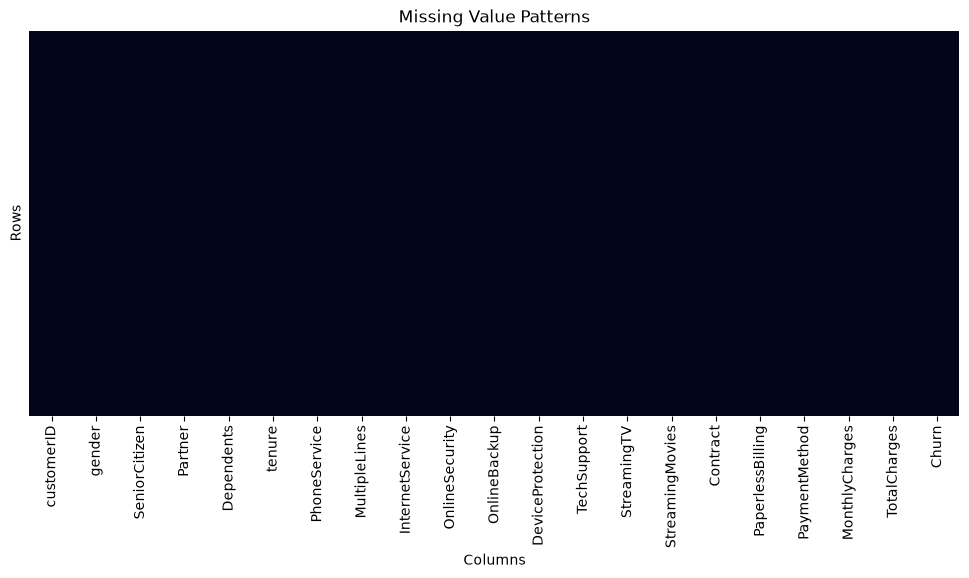

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count missing values in each row
missing_per_row = df.isnull().sum(axis=1)

print("Rows Containing Missing Values:", (missing_per_row > 0).sum())
print("\nMissing Values per Row:")
print(missing_per_row[missing_per_row > 0].head(10))

# Visualize missing value patterns
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Value Patterns")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.show()

### Code Explanation

- `df.isnull().sum(axis=1)` counts missing values in each row.
- `(missing_per_row > 0).sum()` counts rows containing at least one missing value.
- `sns.heatmap()` visualizes where missing values occur.
- `cbar=False` hides the color bar.
- `yticklabels=False` hides individual row labels for readability.

**Expected Insight:**

The output shows how many rows contain missing values. The heatmap helps identify whether missing values appear randomly or in particular patterns.

**AI/ML Use:**

Understanding missingness patterns helps us choose suitable imputation methods and avoid introducing unnecessary bias.

# Section 2: Duplicate Records



# Question 5: Identify Duplicate Records


## Step 1: Understand the concept

Duplicate records are rows that repeat information already present in the dataset.

Pandas uses `duplicated()` to identify repeated rows.

By default, the first occurrence is not marked as a duplicate, but later identical occurrences are marked as duplicates.

**Why is it important?**
- Prevents repeated records from affecting analysis.
- Helps maintain data consistency.
- Reduces the risk of biased statistical results.

## Step 2: Demonstrate the concept

We will identify duplicate rows by comparing all columns.

In customer analytics, repeated customer records may affect customer counts and business reports.


## Step 3: Implement the Concept

In [23]:
# Identify duplicate rows
duplicate_rows = df.duplicated()

print("Duplicate Row Indicators:")
print(duplicate_rows.head(10))

print("\nDuplicate Rows:")
print(df[duplicate_rows].head())

Duplicate Row Indicators:
0    False
1    False
2    False
3    False
4    False
5    False
6    False
7    False
8    False
9    False
dtype: bool

Duplicate Rows:
Empty DataFrame
Columns: [customerID, gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn]
Index: []

[0 rows x 21 columns]


### Code Explanation

- `df.duplicated()` checks whether each row has appeared previously.
- It returns True for repeated occurrences and False otherwise.
- `df[duplicate_rows]` displays rows identified as duplicates.

**Expected Insight:**

The output shows whether duplicate rows exist and displays some duplicate records if found.

**AI/ML Use:**

Duplicate records can unintentionally give repeated examples extra influence during model training and evaluation.

# Question 6: Count Duplicate Records


## Step 1: Understand the concept

Counting duplicates tells us how many rows repeat earlier rows.

**Why is it important?**
- Measures the extent of duplication.
- Helps assess dataset quality.
- Supports decisions about data cleaning.

## Step 2: Demonstrate the concept

We can use `duplicated().sum()` to count all rows identified as duplicates.

This count excludes the first occurrence of each repeated row.


## Step 3: Implement the Concept

In [24]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

Number of Duplicate Rows: 0


### Code Explanation

- `df.duplicated()` identifies duplicate occurrences.
- `.sum()` counts the True values.
- The result represents the number of duplicate rows after their first occurrence.

**Expected Insight:**

The output gives the total duplicate-row count. A value of 0 means no fully identical rows were detected.

**AI/ML Use:**

Duplicate counts help us decide whether deduplication is needed before building a model.

# Question 7: Identify Completely Duplicated Rows


## Step 1: Understand the concept

A completely duplicated row has the same values as another row across every column.

This is different from two rows sharing only a customer ID or email address.

**Why is it important?**
- Detects exact copies of records.
- Helps prevent double-counting.
- Supports reliable data analysis.

## Step 2: Demonstrate the concept

We will use `duplicated(keep=False)` to mark every occurrence of an identical row, including its first occurrence.

This allows us to inspect all rows involved in exact duplication.


## Step 3: Implement the Concept

In [25]:
# Identify all occurrences of completely duplicated rows
all_duplicate_rows = df[df.duplicated(keep=False)]

print("All Completely Duplicated Rows:")
print(all_duplicate_rows)

print("\nTotal Rows Involved in Exact Duplicates:", len(all_duplicate_rows))

All Completely Duplicated Rows:
Empty DataFrame
Columns: [customerID, gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn]
Index: []

[0 rows x 21 columns]

Total Rows Involved in Exact Duplicates: 0


### Code Explanation

- `duplicated(keep=False)` marks every occurrence of duplicated rows.
- `df[...]` filters the dataset to display those rows.
- `len(all_duplicate_rows)` counts all rows involved in exact duplication.

**Expected Insight:**

If no exact duplicates exist, the output will be an empty DataFrame and the row count will be 0.

**AI/ML Use:**

Identifying exact duplicates helps ensure that repeated records do not distort model training or evaluation.

# Question 8: Identify Potential Duplicate Records


## Step 1: Understand the concept

Potential duplicate records may share the same identifier even when their other column values differ.

For example, two rows with the same customerID may represent repeated or conflicting customer records.

**Why is it important?**
- Detects repeated entities.
- Helps identify inconsistent records.
- Supports reliable customer-level analysis.

**Note:**

Repeated identifiers do not always mean records are incorrect. Some datasets legitimately contain multiple records for the same entity.

## Step 2: Demonstrate the concept

We will check whether the customerID column contains repeated values.

If a customer ID occurs multiple times, we should inspect those records before deciding whether they are duplicates.


## Step 3: Implement the Concept

In [26]:
# Check for repeated customer identifiers
if "customerID" in df.columns:
    potential_duplicates = df[
        df.duplicated(subset=["customerID"], keep=False)
    ].sort_values("customerID")

    print("Potential Duplicate Customer Records:")
    print(potential_duplicates)

    print(
        "\nNumber of Rows with Repeated Customer IDs:",
        len(potential_duplicates)
    )
else:
    print("customerID column was not found.")

Potential Duplicate Customer Records:
Empty DataFrame
Columns: [customerID, gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn]
Index: []

[0 rows x 21 columns]

Number of Rows with Repeated Customer IDs: 0


### Code Explanation

- `subset=["customerID"]` checks duplicates using only the customerID column.
- `keep=False` marks all rows whose customerID appears more than once.
- `sort_values("customerID")` groups similar IDs together for easier inspection.
- `len(potential_duplicates)` counts the rows involved.

**Expected Insight:**

The output displays all records with repeated customer IDs. If no IDs repeat, the result is an empty DataFrame.

**AI/ML Use:**

Repeated entities should be investigated to avoid inconsistent records and possible data leakage when splitting data for model training and testing.

# Section 3: Invalid Values

# Question 9: Identify Negative Values Where Inappropriate


## Step 1: Understand the concept

Negative values are not always incorrect. Their validity depends on the meaning of the column.

For example, negative bank balances may be valid, but negative customer tenure is usually invalid.

**Why is it important?**
- Detects potentially incorrect measurements.
- Prevents invalid values from affecting calculations.
- Improves data quality before ML training.

## Step 2: Demonstrate the concept

In the telecom dataset, tenure, MonthlyCharges, and TotalCharges should not normally be negative.

We will convert TotalCharges to numeric temporarily for validation because it may contain blank strings.


## Step 3: Implement the Concept

In [27]:
# Check negative values in appropriate numerical columns
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    if col in df.columns:
        values = pd.to_numeric(df[col], errors="coerce")
        negative_values = df[values < 0]

        print(f"\nNegative values in {col}:")
        print(negative_values[[col]].head())
        print("Count:", int((values < 0).sum()))


Negative values in tenure:
Empty DataFrame
Columns: [tenure]
Index: []
Count: 0

Negative values in MonthlyCharges:
Empty DataFrame
Columns: [MonthlyCharges]
Index: []
Count: 0

Negative values in TotalCharges:
Empty DataFrame
Columns: [TotalCharges]
Index: []
Count: 0


### Code Explanation

- `pd.to_numeric(..., errors="coerce")` converts values to numbers and treats unconvertible values as missing.
- `values < 0` checks for negative values.
- `df[values < 0]` displays the original rows containing negative values.
- `.sum()` counts the negative values.

**Expected Insight:**

The output shows whether negative values exist in the selected columns.

**AI/ML Use:**

Invalid negative values should be investigated and corrected or handled appropriately before model training.

# Question 10: Identify Impossible Values



## Step 1: Understand the concept

Impossible values violate known business rules or logical limits.

Examples include negative age, a percentage above 100 when only 0–100 is allowed, or a tenure value below zero.

**Why is it important?**
- Detects data entry errors.
- Helps enforce business rules.
- Prevents misleading analysis.

## Step 2: Demonstrate the concept

We will check whether tenure falls outside the range of 0 to 72 months in the Telco Customer Churn dataset.

The range should always be based on the dataset definition and business context.


## Step 3: Implement the Concept

In [28]:
# Check reasonable tenure range
if "tenure" in df.columns:
    invalid_tenure = df[
        (df["tenure"] < 0) | (df["tenure"] > 72)
    ]

    print("Invalid Tenure Records:")
    print(invalid_tenure[["customerID", "tenure"]].head())

    print("Invalid Tenure Count:", len(invalid_tenure))

Invalid Tenure Records:
Empty DataFrame
Columns: [customerID, tenure]
Index: []
Invalid Tenure Count: 0


### Code Explanation

- `df["tenure"] < 0` checks values below zero.
- `df["tenure"] > 72` checks values above the chosen upper limit.
- `|` means OR.
- `df[...]` filters rows that violate either condition.

**Expected Insight:**

The output displays records outside the selected tenure range. This range is a validation assumption and should be confirmed against the dataset's business rules.

**AI/ML Use:**

Range validation helps prevent data entry errors from affecting feature distributions and model predictions.

# Question 11: Identify Incorrect Categories


## Step 1: Understand the concept

Incorrect categories are values that do not match the expected categories.

For example, a Churn column expected to contain Yes and No may contain unexpected values such as Maybe or Unknown.

**Why is it important?**
- Detects inconsistent labels.
- Prevents category confusion.
- Helps prepare categorical features for ML.

## Step 2: Demonstrate the concept

We will check whether the Churn column contains values other than Yes and No.

This expected category list comes from the known meaning of the dataset.


## Step 3: Implement the Concept

In [29]:
# Identify unexpected Churn categories
if "Churn" in df.columns:
    expected_categories = {"Yes", "No"}

    actual_categories = set(df["Churn"].dropna().unique())
    unexpected_categories = actual_categories - expected_categories

    print("Actual Categories:", actual_categories)
    print("Unexpected Categories:", unexpected_categories)

Actual Categories: {'Yes', 'No'}
Unexpected Categories: set()


### Code Explanation

- `dropna()` excludes missing values from this category check.
- `unique()` returns distinct values.
- `set()` converts them into a set.
- Set subtraction finds values not included in the expected category list.

**Expected Insight:**

An empty set means no unexpected non-missing Churn categories were found.

**AI/ML Use:**

Consistent category labels help prevent errors during encoding and prediction.

# Question 12: Identify Invalid Dates


## Step 1: Understand the concept

Invalid dates are date values that cannot be interpreted as valid calendar dates.

Examples include 2026-15-40 or 31 February 2026.

**Why is it important?**
- Detects incorrect date entries.
- Supports reliable time-based analysis.
- Helps prepare valid date/time features for ML.

## Step 2: Demonstrate the concept

The Telco Customer Churn dataset does not normally contain a dedicated date column.

We will first identify columns with date-related names. If a date column exists, we can validate its values using Pandas.


## Step 3: Implement the Concept

In [30]:
# Find columns with date-related names
date_candidates = [
    col for col in df.columns
    if any(word in col.lower() for word in ["date", "time", "timestamp"])
]

print("Potential Date Columns:", date_candidates)

# Validate candidate date columns
for col in date_candidates:
    parsed_dates = pd.to_datetime(df[col], errors="coerce")
    invalid_dates = df[col].notna() & parsed_dates.isna()

    print(f"\nInvalid date values in {col}:")
    print(df.loc[invalid_dates, [col]].head())
    print("Invalid Date Count:", int(invalid_dates.sum()))

Potential Date Columns: []


### Code Explanation

- The list comprehension searches column names for date-related words.
- `pd.to_datetime(..., errors="coerce")` converts valid dates and marks invalid values as `NaT`.
- `notna()` identifies original non-missing values.
- `parsed_dates.isna()` identifies values that could not be parsed.
- Combining these conditions identifies invalid date entries rather than original missing values.

**Expected Insight:**

If no date-related columns exist, the candidate list will be empty and no date validation will run.

**AI/ML Use:**

Valid dates support accurate time-based analysis and feature engineering.

# Question 13: Identify Incorrect Data Types


## Step 1: Understand the concept

A data type describes how values are stored, such as integers, decimals, text, or dates.

Sometimes values are stored in an unsuitable type. For example, numeric charges may be stored as text because some records contain blank strings.

**Why is it important?**
- Prevents calculation errors.
- Helps detect inconsistent data.
- Supports correct data preparation for ML.

## Step 2: Demonstrate the concept

In the telecom dataset, TotalCharges may be stored as an object because some values are blank.

We will inspect the current data types and check whether TotalCharges can be converted to numeric values.


## Step 3: Implement the Concept

In [32]:
# Inspect data types
print("Current Data Types:")
print(df.dtypes)

# Check TotalCharges conversion
if "TotalCharges" in df.columns:
    total_charges_numeric = pd.to_numeric(
        df["TotalCharges"],
        errors="coerce"
    )

    invalid_numeric_values = (
        df["TotalCharges"].notna()
        & total_charges_numeric.isna()
    )

    print("\nTotalCharges Original Type:", df["TotalCharges"].dtype)
    print(
        "Values That Cannot Be Converted:",
        int(invalid_numeric_values.sum())
    )

    print("\nInvalid TotalCharges Values:")
    print(df.loc[invalid_numeric_values, ["TotalCharges"]].head())

Current Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

TotalCharges Original Type: object
Values That Cannot Be Converted: 11

Invalid TotalCharges Values:
     TotalCharges
488              
753              
936              
1082             
1340             


# Question 14: Identify Unexpected Values


## Step 1: Understand the concept

Unexpected values are values that do not match the expected data range or business rules.

Examples include unusually high charges, unexpected numerical values, or values that do not match the expected format.

**Why is it important?**
- Detects suspicious data.
- Helps identify data entry errors.
- Improves data quality before analysis and ML training.

## Step 2: Demonstrate the concept

In the telecom dataset, tenure represents the number of months a customer has stayed with the company.

We can inspect the minimum and maximum values of numerical columns to identify values that may need further investigation.

Unusual values are not always incorrect, so we should validate them using business rules.


## Step 3: Implement the Concept

In [33]:
# Inspect minimum and maximum values
numeric_columns = df.select_dtypes(include=np.number).columns

print("Minimum Values:")
print(df[numeric_columns].min())

print("\nMaximum Values:")
print(df[numeric_columns].max())

# Check tenure values outside the expected range
if "tenure" in df.columns:
    unexpected_tenure = df[
        (df["tenure"] < 0) | (df["tenure"] > 72)
    ]

    print("\nUnexpected Tenure Records:")
    print(unexpected_tenure[["customerID", "tenure"]])

    print("Unexpected Tenure Count:", len(unexpected_tenure))

Minimum Values:
SeniorCitizen      0.00
tenure             0.00
MonthlyCharges    18.25
dtype: float64

Maximum Values:
SeniorCitizen       1.00
tenure             72.00
MonthlyCharges    118.75
dtype: float64

Unexpected Tenure Records:
Empty DataFrame
Columns: [customerID, tenure]
Index: []
Unexpected Tenure Count: 0


### Code Explanation

- `select_dtypes(include=np.number)` selects numerical columns.
- `min()` returns the minimum value in each column.
- `max()` returns the maximum value in each column.
- The conditions check whether tenure is below 0 or above 72 months.
- `len()` counts the records that meet the conditions.

**Expected Insight:**

The output displays the numerical ranges and any tenure records outside the selected range.

**AI/ML Use:**

Unexpected values can affect statistical calculations and model predictions. Domain knowledge is needed to decide whether these values are incorrect or valid.

# Question 15: Identify Empty Strings


## Step 1: Understand the concept

An empty string is a text value that contains no characters, represented by "".

Empty strings are different from actual missing values such as NaN.

**Why is it important?**
- Identifies incomplete text fields.
- Prevents empty strings from being treated as valid categories.
- Improves data consistency.

**Real-time Example:**

A customer record may contain an empty string instead of a phone number or address.

## Step 2: Demonstrate the concept

We will inspect text columns and count empty strings.

Using `str.strip()` also helps detect strings that contain only spaces.

This helps us identify text fields that may need cleaning.


## Step 3: Implement the Concept

In [34]:
# Identify empty strings in text columns
text_columns = df.select_dtypes(
    include=["object", "string"]
).columns

empty_string_counts = {}

for col in text_columns:
    cleaned_values = df[col].astype("string").str.strip()
    empty_string_counts[col] = cleaned_values.eq("").sum()

print("Empty Strings by Column:")
print(empty_string_counts)

print("\nColumns Containing Empty Strings:")
print({
    col: count
    for col, count in empty_string_counts.items()
    if count > 0
})

Empty Strings by Column:
{'customerID': np.int64(0), 'gender': np.int64(0), 'Partner': np.int64(0), 'Dependents': np.int64(0), 'PhoneService': np.int64(0), 'MultipleLines': np.int64(0), 'InternetService': np.int64(0), 'OnlineSecurity': np.int64(0), 'OnlineBackup': np.int64(0), 'DeviceProtection': np.int64(0), 'TechSupport': np.int64(0), 'StreamingTV': np.int64(0), 'StreamingMovies': np.int64(0), 'Contract': np.int64(0), 'PaperlessBilling': np.int64(0), 'PaymentMethod': np.int64(0), 'TotalCharges': np.int64(11), 'Churn': np.int64(0)}

Columns Containing Empty Strings:
{'TotalCharges': np.int64(11)}


### Code Explanation

- `select_dtypes()` selects text columns.
- `astype("string")` converts the values to a string-compatible type.
- `str.strip()` removes leading and trailing spaces.
- `eq("")` checks for empty strings.
- `sum()` counts the empty strings in each column.
- The dictionary comprehension displays only columns with empty strings.

**Expected Insight:**

The output identifies text columns containing empty strings. If the final dictionary is empty, no empty strings were detected.

**AI/ML Use:**

Empty strings may need to be converted into missing values before imputation or categorical encoding.

# Question 16: Identify Null-Like Values


## Step 1: Understand the concept

Null-like values are text entries that may represent missing information but are stored as ordinary strings.

Examples include:
- "NA"
- "N/A"
- "null"
- "None"
- "missing"

**Why is it important?**
- Detects hidden missing data.
- Prevents incorrect category counts.
- Helps standardize data before analysis.

## Step 2: Demonstrate the concept

We will search text columns for common null-like labels.

The search ignores capitalization and spaces around the values.

These labels should be checked before changing them because their meaning depends on the dataset.


## Step 3: Implement the Concept

In [36]:
# Identify common null-like values
null_like_values = {
    "na", "n/a", "null", "none", "missing", "unknown"
}

text_columns = df.select_dtypes(
    include=["object", "string"]
).columns

for col in text_columns:
    cleaned_values = (
        df[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    null_like_mask = cleaned_values.isin(null_like_values)

    if null_like_mask.any():
        print(f"\nNull-like values in {col}:")
        print(df.loc[null_like_mask, [col]].head())

        print("Count:", int(null_like_mask.sum()))

### Code Explanation

- `null_like_values` stores common text labels that may represent missing data.
- `astype("string")` allows text processing.
- `str.strip()` removes surrounding spaces.
- `str.lower()` makes the comparison case-insensitive.
- `isin()` checks whether values match any listed label.
- `null_like_mask.any()` checks whether any matches exist.
- `df.loc[]` displays matching records.

**Expected Insight:**

The output displays text columns containing the specified null-like values. If nothing is printed, none of the listed labels were found.

**AI/ML Use:**

Null-like values should be standardized if they genuinely represent missing data. Values such as "Unknown" should not automatically be replaced without checking their meaning.